In [21]:

import cv2
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import random


import tensorflow as tf
from tensorflow.keras.losses import binary_crossentropy
from keras.layers import Conv2D, BatchNormalization, Input, MaxPooling2D, UpSampling2D
from keras.models import Model
from keras.callbacks import EarlyStopping

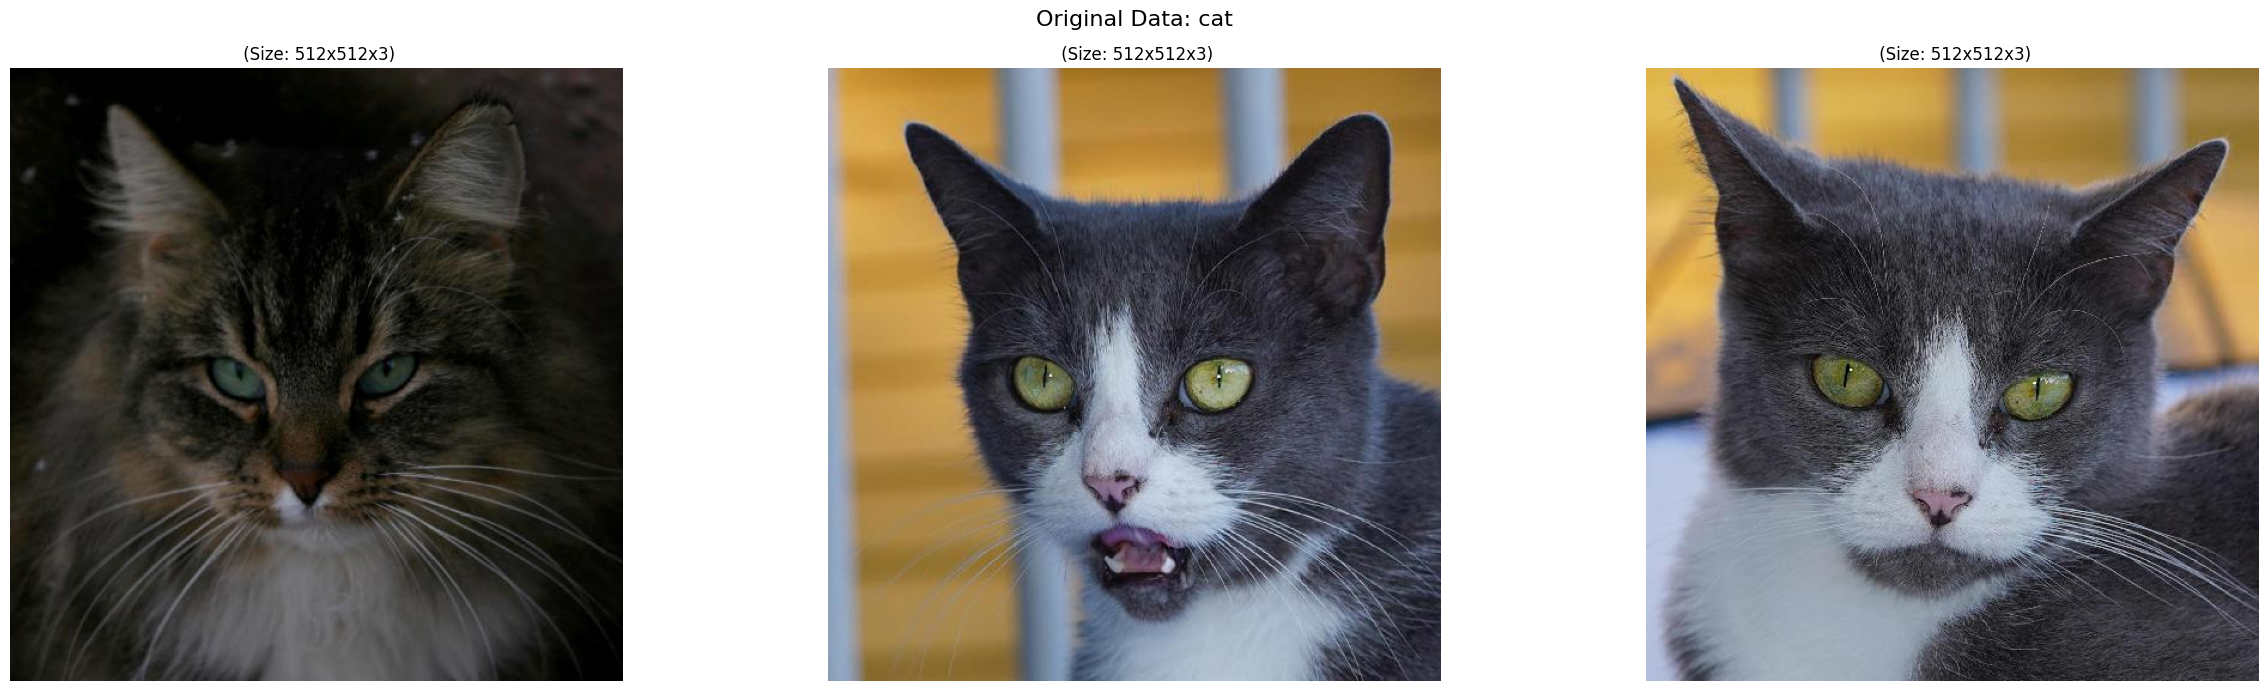

In [22]:
train_folder= '/Users/marek/animals/afhq/train'
test_folder = '/Users/marek/animals/afhq/val'
files=['cat']

for file in files:
    path = os.path.join(train_folder, file)
    fig, axes = plt.subplots(1, 3, figsize=(25, 7))

    for i, img_name in enumerate(os.listdir(path)[:3]):
        img_array = cv2.imread(os.path.join(path, img_name))
        if img_array is not None:
            img_array_rgb = cv2.cvtColor(img_array, cv2.COLOR_BGR2RGB)
            height, width,ch = img_array.shape
            axes[i].imshow(img_array_rgb)
            axes[i].set_title(f" (Size: {width}x{height}x{ch})")
            axes[i].axis('off')
        else:
            axes[i].set_title(f"Failed to load {img_name}")
            axes[i].axis('off')

    plt.suptitle(f'Original Data: {file}', fontsize=16)
    plt.tight_layout()
    plt.show()
            




In [23]:
import tensorflow as tf

IMAGE_SIZE =  (64,64)

print('Training Images:')
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_folder,
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=16)

print('Testing Images:')
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_folder, 
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=16)

Training Images:
Found 5153 files belonging to 1 classes.
Testing Images:
Found 500 files belonging to 1 classes.


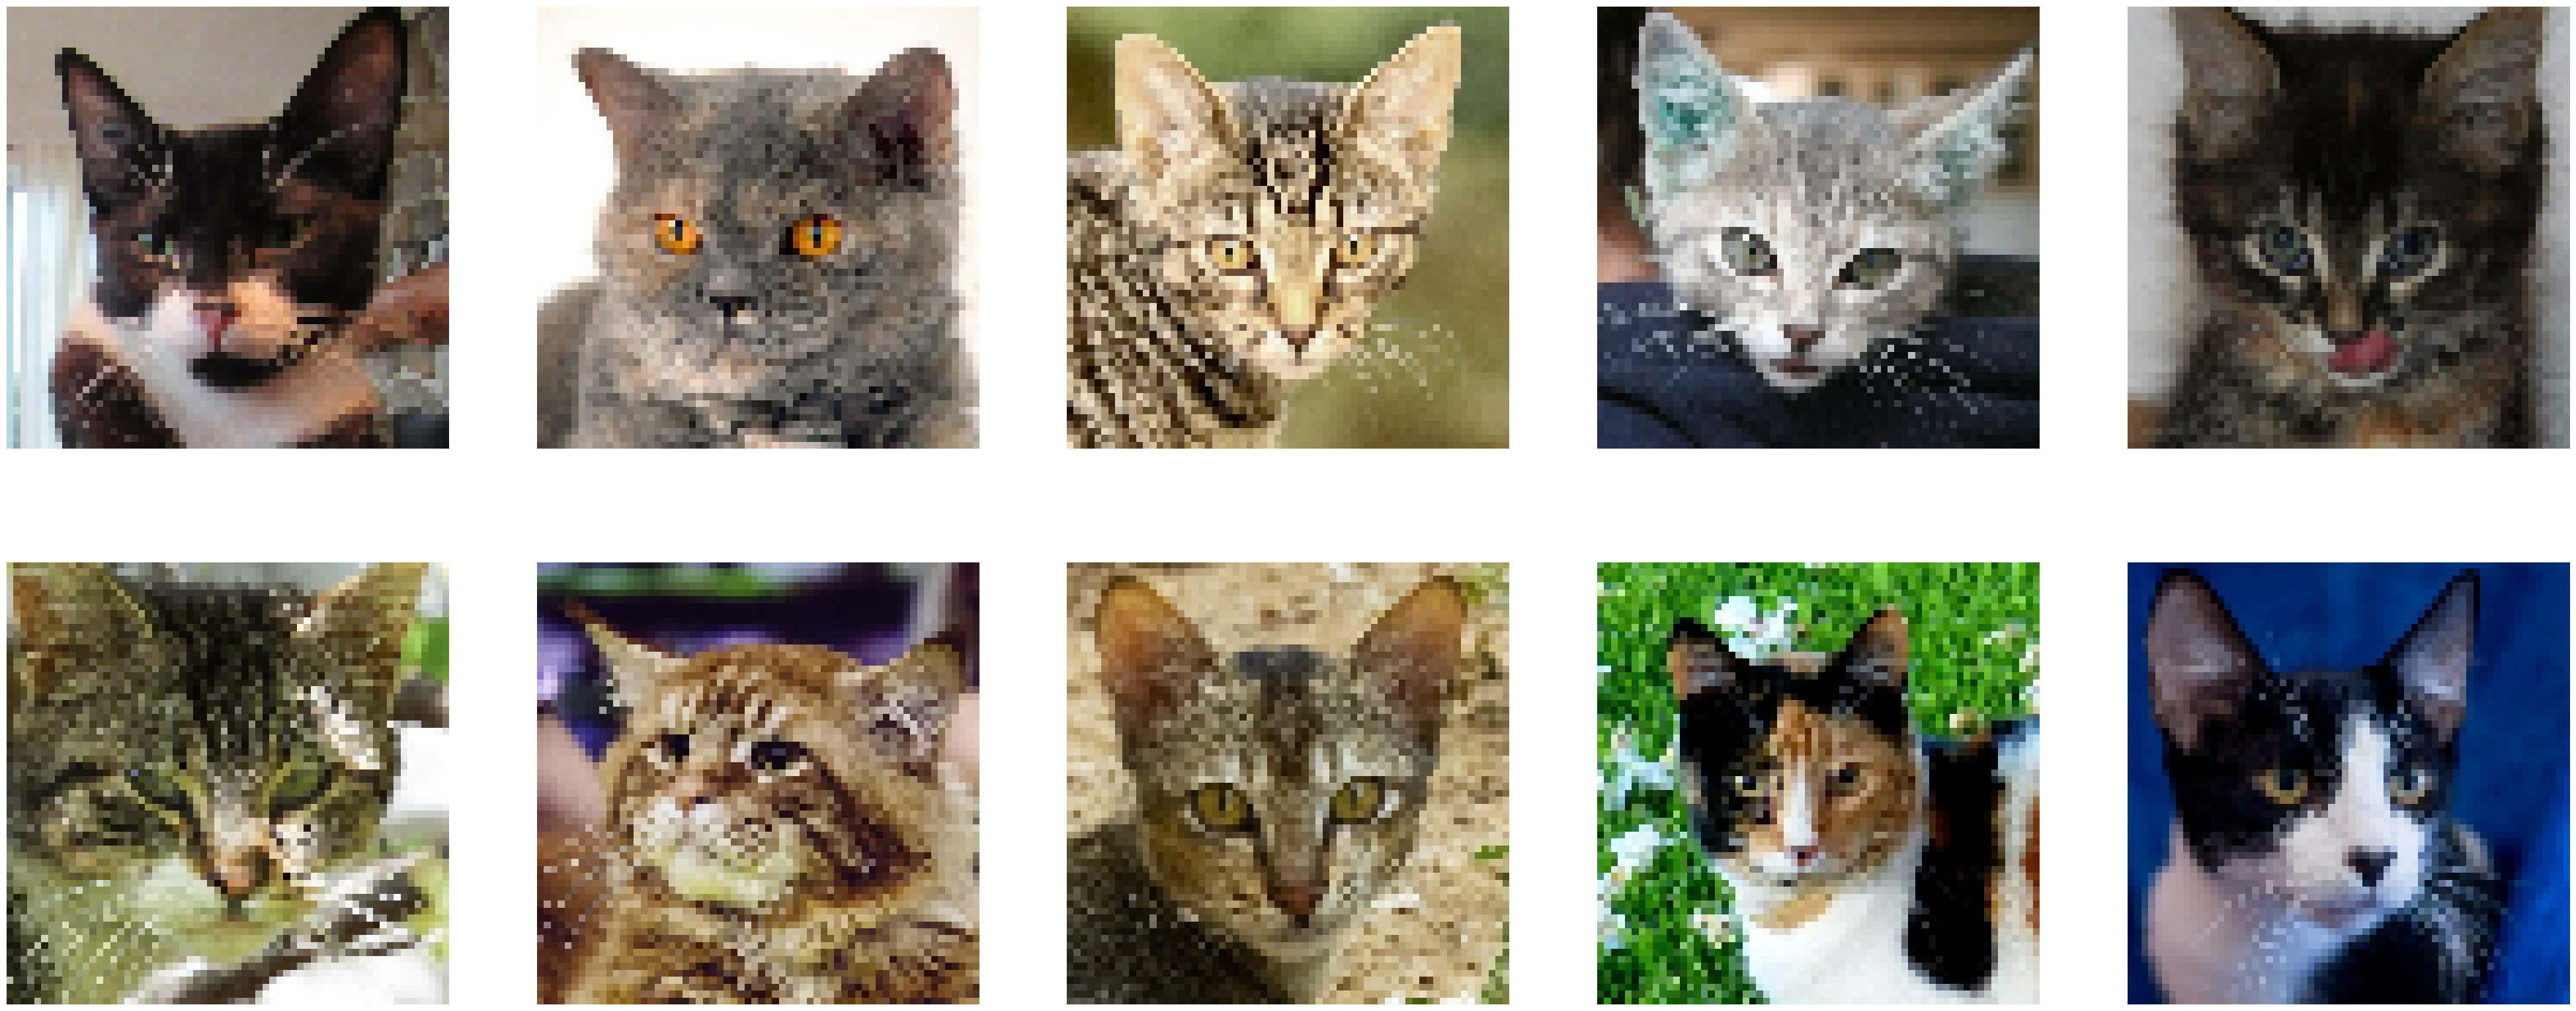

In [24]:
def plot_images(dataset, num_images=10):
    plt.figure(figsize=(50, 20))
    for images, _ in dataset.take(1):
        for i in range(num_images):
            plt.subplot(2, 5, i+1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.axis('off')
    plt.show()

plot_images(train_ds)

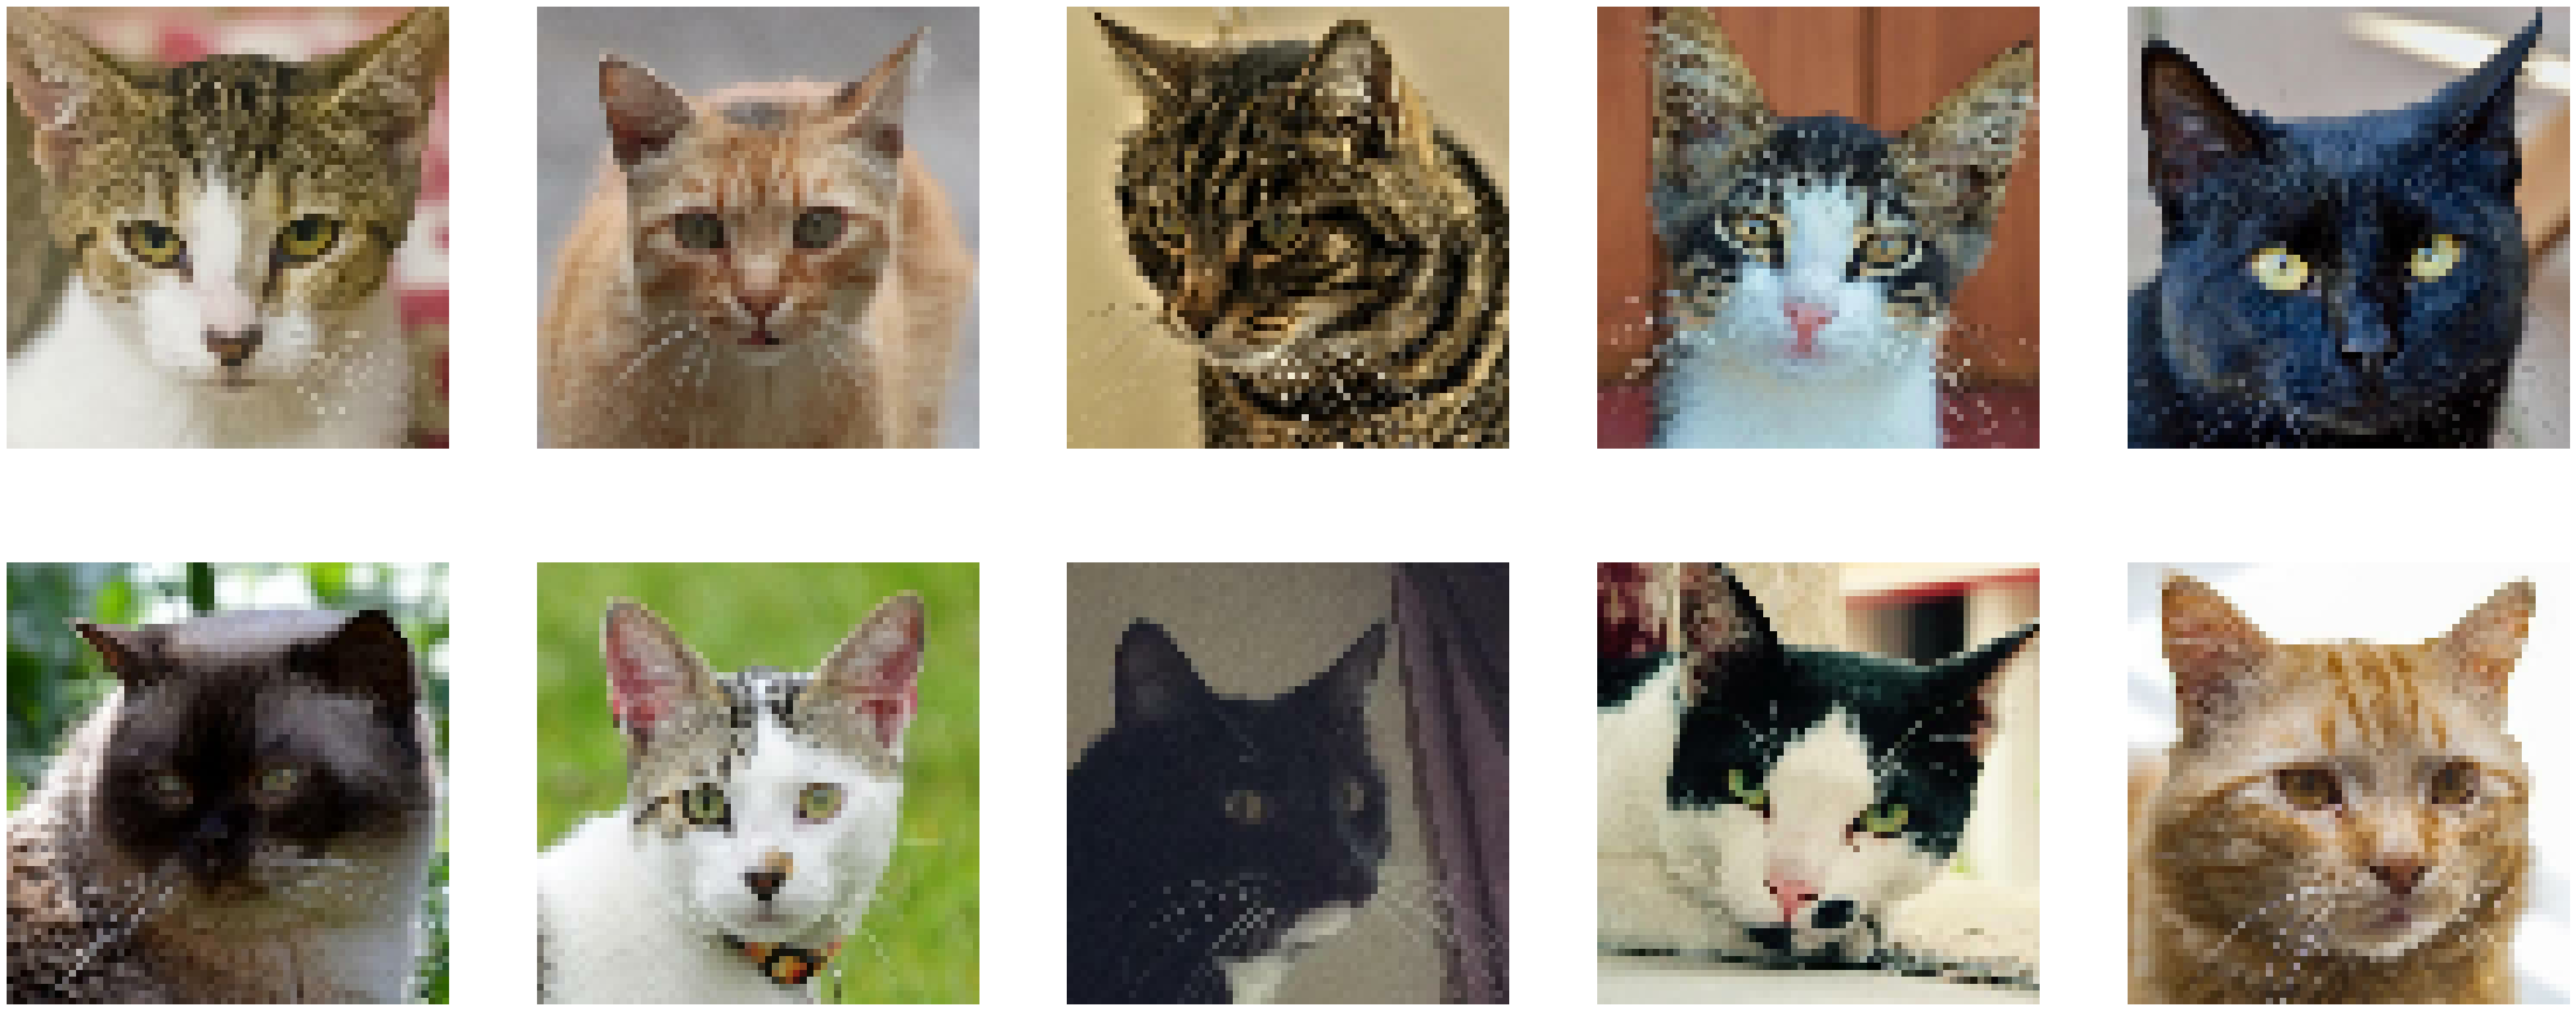

In [25]:
plot_images(test_ds)

In [26]:
X_train = []
X_test = []

for images, _ in train_ds:
    X_train.append(images.numpy())

for images, _ in test_ds:
    X_test.append(images.numpy())
    
X_train = np.concatenate(X_train, axis=0)
X_test = np.concatenate(X_test, axis=0)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (5153, 64, 64, 3)
X_test shape: (500, 64, 64, 3)


In [27]:
X_train.max()

255.0

In [28]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [29]:
X_train.max()

1.0

In [30]:
noise_factor = 0.25

X_train_noise = X_train + noise_factor * np.random.normal(loc = 0., scale = 1., size = X_train.shape)
X_test_noise = X_test + noise_factor * np.random.normal(loc = 0., scale = 1., size = X_test.shape)

In [31]:
X_train.shape

(5153, 64, 64, 3)

In [32]:
X_train_noise.shape

(5153, 64, 64, 3)

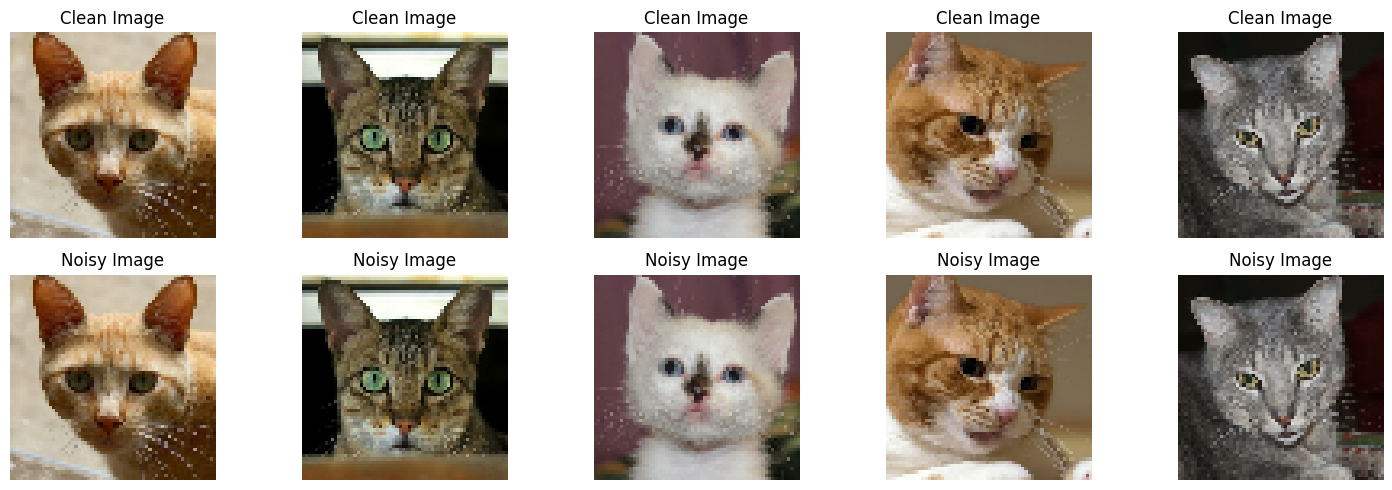

In [33]:
def visualize_clean_vs_noisy(X, X_noise, num_images=5):
    plt.figure(figsize=(15, 5))  
    
    for i in range(num_images):
        index = np.random.randint(0, X_train.shape[0])

        plt.subplot(2, num_images, i + 1)
        plt.imshow(X[index])
        plt.title("Clean Image")
        plt.axis('off')  

        plt.subplot(2, num_images, num_images + i + 1)
        plt.imshow(X[index])
        plt.title("Noisy Image")
        plt.axis('off')  

    plt.tight_layout()  
    plt.show()

visualize_clean_vs_noisy(X_train, X_train_noise, num_images=5)

In [34]:
encoder_input = Input(shape=X_train.shape[1:])
x = Conv2D(32, (3, 3), activation='relu', padding='same')(encoder_input)
x = BatchNormalization()(x)
x = MaxPooling2D(pool_size=(2, 2), padding='same')(x) 
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
encoded = MaxPooling2D(pool_size=(2, 2), padding='same')(x)  

In [35]:
x = Conv2D(32, (3,3), activation = 'relu', padding = 'same')(encoded)
x = BatchNormalization()(x)
x = UpSampling2D()(x)
x = Conv2D(32, (3,3), activation = 'relu', padding = 'same')(x)
x = BatchNormalization()(x)
x = UpSampling2D()(x)
decoded = Conv2D(3, (3,3), activation = 'sigmoid', padding = 'same')(x)

In [36]:
autoencoder = Model(encoder_input, decoded, name = 'Denoising_Model')
autoencoder.summary()

Model: "Denoising_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 64, 64, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 32, 32, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 32, 32, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 16, 16, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 16, 16, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_2 (UpSampling2D)       │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 32, 32, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 32, 32, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_3 (UpSampling2D)       │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 64, 64, 3)           │             867 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 30,019 (117.26 KB)

 Trainable params: 29,763 (116.26 KB)

 Non-trainable params: 256 (1.00 KB)

In [37]:
autoencoder.compile(loss = 'binary_crossentropy', optimizer = 'adam')
early_stopping = EarlyStopping(
    monitor='val_loss',  
    patience=10,         
    restore_best_weights=True 
)

history = autoencoder.fit(
    X_train_noise, X_train,
    batch_size=16,
    epochs=100,
    validation_data=(X_test_noise, X_test),
    callbacks=[early_stopping], 
    verbose=2
)

Epoch 1/100
323/323 - 22s - 67ms/step - loss: 0.5750 - val_loss: 0.5770
Epoch 2/100
323/323 - 18s - 56ms/step - loss: 0.5646 - val_loss: 0.5612
Epoch 3/100
323/323 - 18s - 55ms/step - loss: 0.5632 - val_loss: 0.5592
Epoch 4/100
323/323 - 18s - 57ms/step - loss: 0.5624 - val_loss: 0.5583
Epoch 5/100
323/323 - 18s - 55ms/step - loss: 0.5615 - val_loss: 0.5573
Epoch 6/100
323/323 - 19s - 60ms/step - loss: 0.5618 - val_loss: 0.5577
Epoch 7/100
323/323 - 21s - 65ms/step - loss: 0.5611 - val_loss: 0.5567
Epoch 8/100
323/323 - 21s - 64ms/step - loss: 0.5608 - val_loss: 0.5565
Epoch 9/100
323/323 - 39s - 121ms/step - loss: 0.5607 - val_loss: 0.5562
Epoch 10/100
323/323 - 18s - 56ms/step - loss: 0.5602 - val_loss: 0.5639
Epoch 11/100
323/323 - 18s - 55ms/step - loss: 0.5601 - val_loss: 0.5563
Epoch 12/100
323/323 - 21s - 66ms/step - loss: 0.5603 - val_loss: 0.5561
Epoch 13/100
323/323 - 18s - 56ms/step - loss: 0.5597 - val_loss: 0.5557
Epoch 14/100
323/323 - 18s - 56ms/step - loss: 0.5597 - val

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7932008172713303..1.820972446164002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8063865169546458..1.412989358985444].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5871655593597419..1.6798026050867656].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.6786651222498173..1.670464475966803].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5081488291734514..1.697978599791031].


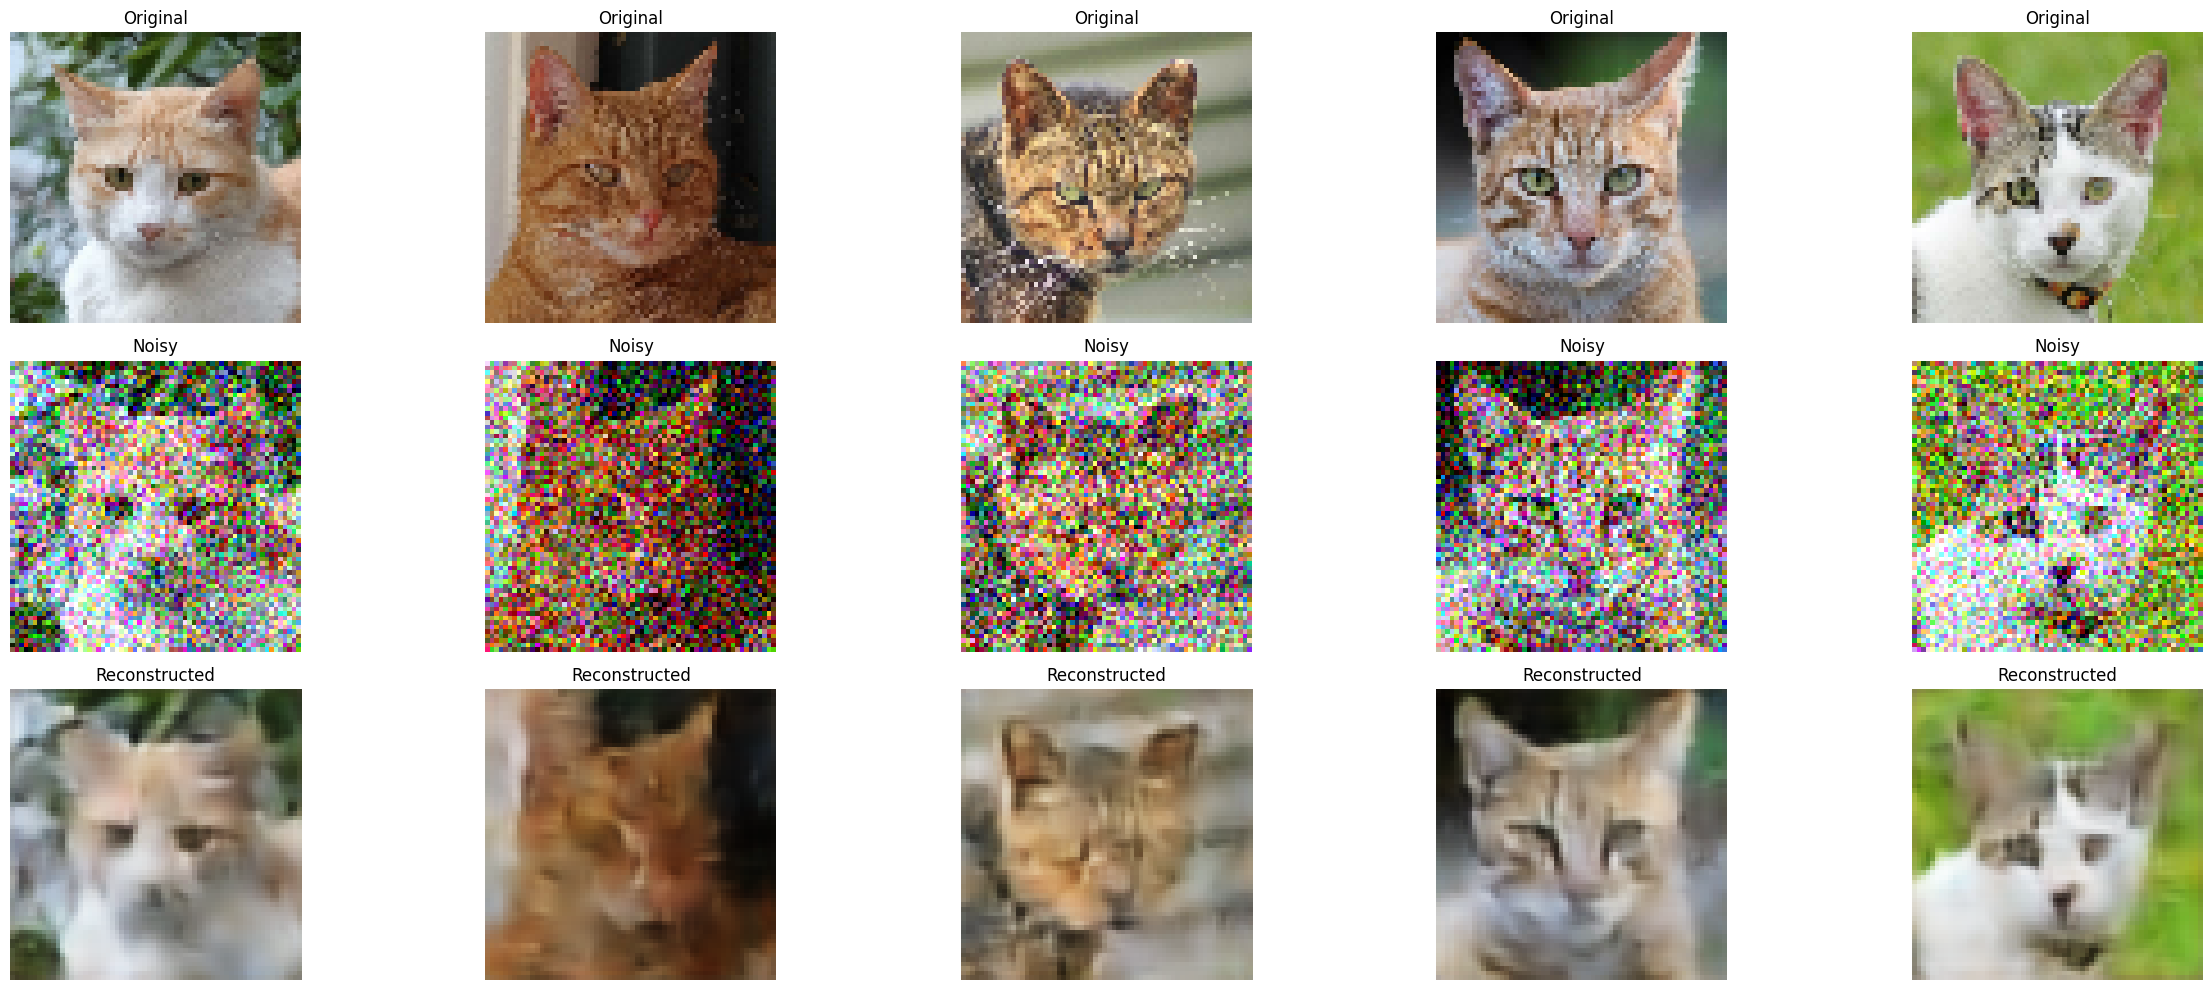

In [38]:
def visualize_original_noise_reconstructed(autoencoder, X, X_noise, num_images=5):
    reconstructed_images = autoencoder.predict(X_test_noise)
    
    plt.figure(figsize=(25, 10)) 

    for i in range(num_images):
        plt.subplot(3, num_images, i + 1)
        plt.imshow(X[i])
        plt.title("Original")
        plt.axis('off')

        plt.subplot(3, num_images, num_images + i + 1)
        plt.imshow(X_noise[i])
        plt.title("Noisy")
        plt.axis('off') 

        plt.subplot(3, num_images, 2 * num_images + i + 1)
        plt.imshow(reconstructed_images[i])
        plt.title("Reconstructed")
        plt.axis('off')  

    plt.tight_layout()  
    plt.show()

visualize_original_noise_reconstructed(autoencoder, X_test, X_test_noise, num_images=5)

# My computer was only able to do 59 epochs, that is why the generated images are looking like this. 
# I changed the batch size from 32 to 16 to make it easier for my computer. 
# But I believe this code is able to generate very good cat faces.

